# Sistematização: Analisador e Filtro de Sinais
### Série de Fourier · Transformada de Fourier · Transformada de Laplace

**Integrantes:** Nome 1 · Nome 2 · Nome 3 *(substituir)*
**Disciplina / Turma:** *(preencher)*  **Data:** *(preencher)*

---
**Sinal escolhido:** sinal sintético (soma de senoides + ruído), o caso mais controlado. Como sabemos exatamente o que é "sinal limpo" e o que é "interferência", conseguimos **medir** a qualidade da filtragem (SNR) e não apenas olhar os gráficos.

**Roteiro do notebook**

| Etapa | Tema | Unidade |
|---|---|---|
| 1 | Série de Fourier da onda quadrada (coeficientes, forma complexa, Gibbs) | 1 e 2 |
| 2 | FFT do sinal: espectro, amostragem e Nyquist | 3 |
| 3 | Filtro (notch 60 Hz + passa-baixas), IFFT e comparação antes/depois | 3 |
| 4 | Filtro como sistema linear: H(s), polos e zeros, estabilidade | 4 |

> **Como executar:** `Ambiente de execução → Executar tudo` no Google Colab (ou `jupyter notebook` localmente). Todas as bibliotecas já vêm instaladas no Colab. Os arquivos de áudio são gerados na pasta `data/`.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy import signal, fft
from scipy.io import wavfile
from IPython.display import display, Audio

os.makedirs("data", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.figsize": (9, 3.6), "axes.spines.top": False,
                     "axes.spines.right": False})
sp.init_printing(use_latex="mathjax")
print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 0. O sinal de trabalho

Geramos 2 s de "áudio" amostrado a **fs = 8000 Hz** (qualidade de telefonia), contendo:

| Componente | Frequência | Amplitude | Papel |
|---|---|---|---|
| Nota Lá4 | 440 Hz | 1,0 | sinal útil (fundamental) |
| 2º harmônico | 880 Hz | 0,5 | sinal útil (harmônico) |
| Zumbido da rede elétrica | 60 Hz | 0,8 | **interferência** narrowband |
| Ruído branco gaussiano | banda toda | σ = 0,15 | **interferência** broadband |

O sinal "limpo" (440 + 880 Hz) é guardado apenas para **avaliar** o resultado. O filtro, claro, só enxerga o sinal ruidoso.

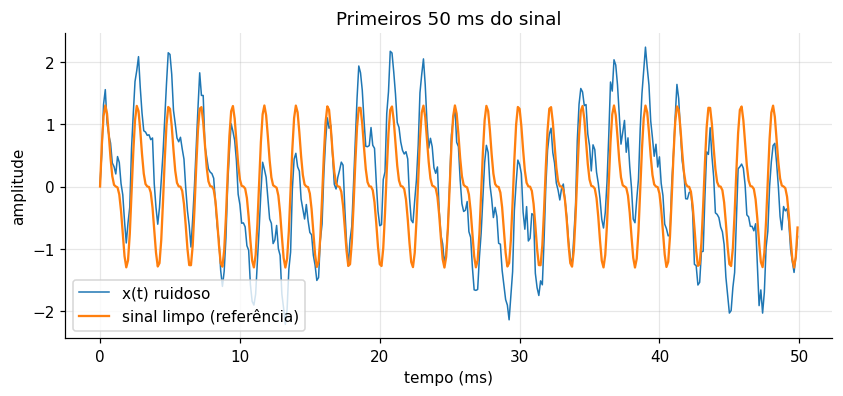

In [2]:
fs = 8000                      # taxa de amostragem (Hz) — guarde este valor!
T  = 2.0                       # duração (s)
t  = np.arange(0, T, 1/fs)     # vetor de tempo
rng = np.random.default_rng(42)  # semente fixa => reprodutível

limpo = 1.0*np.sin(2*np.pi*440*t) + 0.5*np.sin(2*np.pi*880*t)
hum   = 0.8*np.sin(2*np.pi*60*t)
ruido = 0.15*rng.standard_normal(t.size)
x = limpo + hum + ruido        # sinal que "chega" ao analisador

# Salvar o sinal (CSV + WAV) para o repositório
np.savetxt("data/sinal_ruidoso.csv", np.c_[t, x], delimiter=",", header="t_s,x", comments="")

def salvar_wav(nome, sig, escala):
    wavfile.write(nome, fs, (sig*escala*32767).astype(np.int16))

ESC = 0.9/np.max(np.abs(x))    # mesma escala p/ antes e depois => volume comparável
salvar_wav("data/antes_ruidoso.wav", x, ESC)
salvar_wav("data/limpo_referencia.wav", limpo, ESC)

fig, ax = plt.subplots()
m = t < 0.05
ax.plot(t[m]*1e3, x[m], lw=1, label="x(t) ruidoso")
ax.plot(t[m]*1e3, limpo[m], lw=1.5, label="sinal limpo (referência)")
ax.set(xlabel="tempo (ms)", ylabel="amplitude", title="Primeiros 50 ms do sinal")
ax.legend(); plt.show()
Audio(x*ESC, rate=fs)

**Leitura do gráfico.** No tempo, o sinal ruidoso mostra uma oscilação lenta sobreposta (o zumbido de 60 Hz, período ≈ 16,7 ms) e um "tremido" fino (o ruído branco). Já a nota e o harmônico, mais rápidos, ficam escondidos. Só no domínio da frequência as componentes vão se separar (Etapa 2).

---
# Etapa 1 · Aproximando funções com ondas (Unidades 1 e 2)

**Ideia central:** as funções $\sin(nx)$ e $\cos(nx)$ são **ortogonais** em $[-\pi,\pi]$:

$$\int_{-\pi}^{\pi}\sin(mx)\sin(nx)\,dx=\pi\,\delta_{mn},\qquad \int_{-\pi}^{\pi}\sin(mx)\cos(nx)\,dx=0$$

Por isso formam uma **base**: para extrair o "quanto" de cada onda há em $f$, basta projetar $f$ nela, e os coeficientes não interferem entre si.

Vamos aproximar a **onda quadrada** $f(x)=\operatorname{sgn}(x)$ em $[-\pi,\pi]$ (período $2\pi$):

$$f(x)\sim \frac{a_0}{2}+\sum_{n=1}^{\infty}\big(a_n\cos nx+b_n\sin nx\big),\quad a_n=\frac1\pi\!\int_{-\pi}^{\pi}\!f\cos nx\,dx,\quad b_n=\frac1\pi\!\int_{-\pi}^{\pi}\!f\sin nx\,dx$$

### 1.1 Coeficientes (cálculo simbólico com SymPy)

In [3]:
x_ = sp.symbols("x", real=True)
n_ = sp.symbols("n", integer=True, positive=True)
pi = sp.pi

# f = -1 em (-pi,0) e +1 em (0,pi)
a0 = (1/pi)*(sp.integrate(-1, (x_, -pi, 0)) + sp.integrate(1, (x_, 0, pi)))
an = (1/pi)*(sp.integrate(-sp.cos(n_*x_), (x_, -pi, 0)) + sp.integrate(sp.cos(n_*x_), (x_, 0, pi)))
bn = (1/pi)*(sp.integrate(-sp.sin(n_*x_), (x_, -pi, 0)) + sp.integrate(sp.sin(n_*x_), (x_, 0, pi)))
an, bn = sp.simplify(an), sp.simplify(bn)

display(sp.Eq(sp.Symbol("a_0"), a0))
display(sp.Eq(sp.Symbol("a_n"), an))
display(sp.Eq(sp.Symbol("b_n"), bn))
print("b_n para n = 1..8:", [sp.nsimplify(bn.subs(n_, k)) for k in range(1, 9)])

a₀ = 0

aₙ = 0

       ⎛        n⎞
     2⋅⎝1 - (-1) ⎠
bₙ = ─────────────
          π⋅n     

b_n para n = 1..8: [4/pi, 0, 4/(3*pi), 0, 4/(5*pi), 0, 4/(7*pi), 0]


**Interpretação.** $a_0=a_n=0$ porque a onda quadrada é **ímpar** (simetria: só sobram senos). Além disso, $b_n=\dfrac{2\,(1-(-1)^n)}{\pi n}$, isto é,

$$b_n=\begin{cases}\dfrac{4}{\pi n}, & n\ \text{ímpar}\\[2mm] 0, & n\ \text{par}\end{cases}\qquad\Longrightarrow\qquad f(x)\sim\frac4\pi\left(\sin x+\frac{\sin 3x}{3}+\frac{\sin 5x}{5}+\cdots\right)$$

Só existem harmônicos **ímpares** e a amplitude cai como $1/n$ (lentamente, sinal de que a função tem uma descontinuidade).

### 1.2 Somando cada vez mais harmônicos

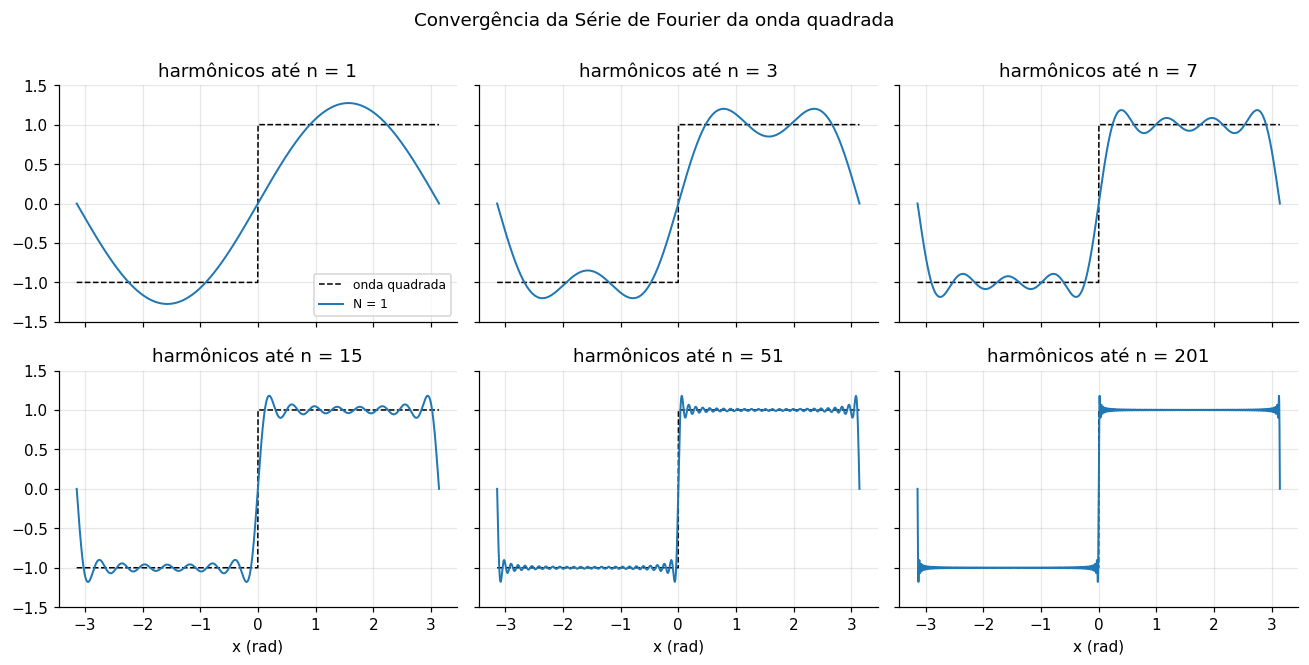

In [4]:
def soma_parcial(xv, N):
    # soma de Fourier com harmônicos ímpares até N (forma trigonométrica)
    s = np.zeros_like(xv)
    for k in range(1, N+1, 2):
        s += 4/(np.pi*k)*np.sin(k*xv)
    return s

xv = np.linspace(-np.pi, np.pi, 4001)
quadrada = np.sign(xv)

fig, axs = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)
for ax, N in zip(axs.ravel(), [1, 3, 7, 15, 51, 201]):
    ax.plot(xv, quadrada, "k--", lw=1, label="onda quadrada")
    ax.plot(xv, soma_parcial(xv, N), lw=1.3, label=f"N = {N}")
    ax.set_title(f"harmônicos até n = {N}"); ax.set_ylim(-1.5, 1.5)
axs[0, 0].legend(loc="lower right", fontsize=8)
for ax in axs[1]: ax.set_xlabel("x (rad)")
fig.suptitle("Convergência da Série de Fourier da onda quadrada", y=1.0)
plt.tight_layout(); plt.show()

**Interpretação.** Com $N=1$ temos só uma senoide; com $N=3$ já aparece o "patamar"; a cada harmônico somado, o topo fica mais plano e a subida mais íngreme. A aproximação converge **em média quadrática** (energia do erro → 0) e pontualmente nos pontos de continuidade. Mas repare nos "chifres" junto à descontinuidade: eles não desaparecem.

### 1.3 O fenômeno de Gibbs

N =     5  pico = 1.1884   sobressinal = 9.42 % do salto
N =    11  pico = 1.1813   sobressinal = 9.07 % do salto
N =    21  pico = 1.1797   sobressinal = 8.98 % do salto
N =    51  pico = 1.1791   sobressinal = 8.96 % do salto
N =   101  pico = 1.1790   sobressinal = 8.95 % do salto
N =   301  pico = 1.1790   sobressinal = 8.95 % do salto


N =  1001  pico = 1.1790   sobressinal = 8.95 % do salto

Limite teórico (N→∞): (Si(π)/π − 1/2)·100 = 8.95 % do salto


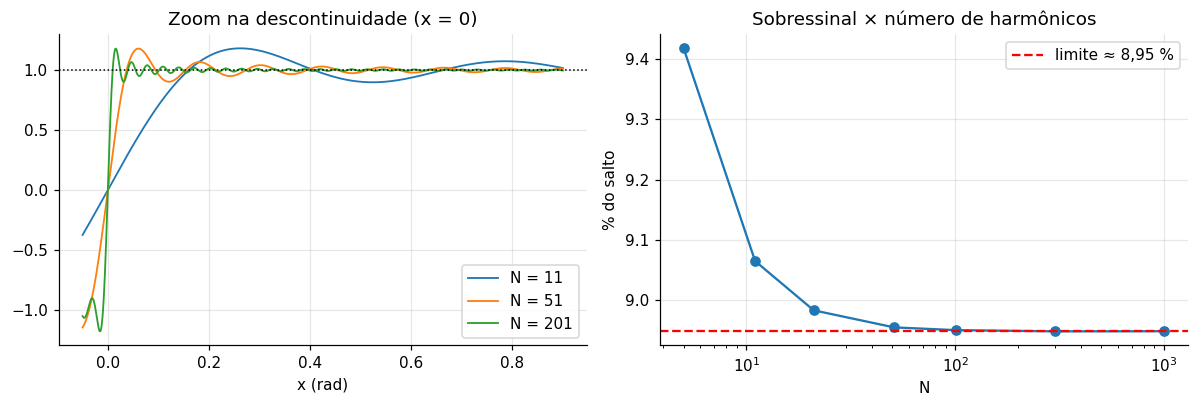

In [5]:
xf = np.linspace(0, np.pi, 40001)
Ns = [5, 11, 21, 51, 101, 301, 1001]
over = []
for N in Ns:
    pico = soma_parcial(xf, N).max()
    over.append((pico - 1)/2*100)      # % do "salto" (que vale 2)
    print(f"N = {N:5d}  pico = {pico:.4f}   sobressinal = {over[-1]:.2f} % do salto")
print(f"\nLimite teórico (N→∞): (Si(π)/π − 1/2)·100 = {(float(sp.Si(sp.pi))/np.pi - 0.5)*100:.2f} % do salto")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
xz = np.linspace(-0.05, 0.9, 4000)
for N in [11, 51, 201]:
    axs[0].plot(xz, soma_parcial(xz, N), lw=1.2, label=f"N = {N}")
axs[0].axhline(1, color="k", ls=":", lw=1)
axs[0].set(title="Zoom na descontinuidade (x = 0)", xlabel="x (rad)"); axs[0].legend()
axs[1].semilogx(Ns, over, "o-")
axs[1].axhline((float(sp.Si(sp.pi))/np.pi - 0.5)*100, color="r", ls="--", label="limite ≈ 8,95 %")
axs[1].set(title="Sobressinal × número de harmônicos", xlabel="N", ylabel="% do salto"); axs[1].legend()
plt.tight_layout(); plt.show()

**Interpretação.** Ao aumentar $N$, o "chifre" fica **mais estreito** (ele se aproxima da descontinuidade), mas sua **altura não diminui**: estaciona em ≈ 8,95 % do salto (≈ 17,9 % acima do patamar de $+1$). Esse é o **fenômeno de Gibbs**: uma soma contínua de senoides nunca consegue "virar a esquina" instantaneamente. A convergência é em média quadrática (a energia do erro vai a zero), mas **não uniforme** em torno da descontinuidade. Isso tem consequência direta nas Etapas 3 e 4: filtros do tipo "parede de tijolo" (cortar bins abruptamente) geram *ringing* justamente por Gibbs.

### 1.4 Forma complexa da série

Usando $\cos nx=\frac{e^{jnx}+e^{-jnx}}2$ e $\sin nx=\frac{e^{jnx}-e^{-jnx}}{2j}$:

$$f(x)=\sum_{n=-\infty}^{\infty}c_n\,e^{jnx},\qquad c_n=\frac1{2\pi}\int_{-\pi}^{\pi}f(x)\,e^{-jnx}\,dx$$

As exponenciais $e^{jnx}$ também são ortogonais, e $c_n=\dfrac{a_n-jb_n}{2}$ para $n>0$, com $c_{-n}=\overline{c_n}$ (sinal real).

         n + 1/2      
     (-1)           ⅈ 
cₙ = ─────────── - ───
         π⋅n       π⋅n

n=1:  c_n (SymPy) = 0.0000-0.6366j    -2j/(πn) ou 0 = -0.0000-0.6366j
n=2:  c_n (SymPy) = 0.0000+0.0000j    -2j/(πn) ou 0 = 0.0000
n=3:  c_n (SymPy) = 0.0000-0.2122j    -2j/(πn) ou 0 = -0.0000-0.2122j
n=4:  c_n (SymPy) = 0.0000+0.0000j    -2j/(πn) ou 0 = 0.0000
n=5:  c_n (SymPy) = 0.0000-0.1273j    -2j/(πn) ou 0 = -0.0000-0.1273j
n=6:  c_n (SymPy) = 0.0000+0.0000j    -2j/(πn) ou 0 = 0.0000

Forma complexa == forma trigonométrica? True


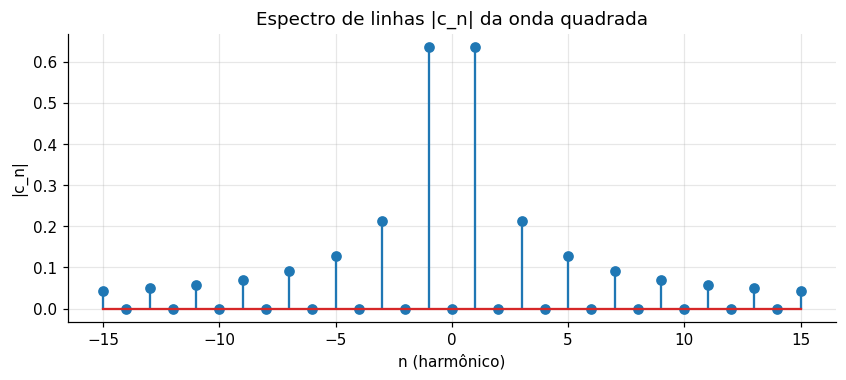

In [6]:
cn = (1/(2*pi))*(sp.integrate(-sp.exp(-sp.I*n_*x_), (x_, -pi, 0)) + sp.integrate(sp.exp(-sp.I*n_*x_), (x_, 0, pi)))
cn = sp.simplify(cn)
display(sp.Eq(sp.Symbol("c_n"), cn))

# Conferência numérica: c_n = -2j/(pi n) para n ímpar, 0 para n par
for k in range(1, 7):
    simb = complex(cn.subs(n_, k).evalf())
    esperado = -2j/(np.pi*k) if k % 2 else 0
    print(f"n={k}:  c_n (SymPy) = {simb:.4f}    -2j/(πn) ou 0 = {esperado:.4f}")

def soma_complexa(xv, N):
    s = np.zeros_like(xv, dtype=complex)
    for k in range(-N, N+1):
        if k % 2:                               # só ímpares (em Python, (-3)%2 == 1)
            s += (-2j/(np.pi*k))*np.exp(1j*k*xv)
    return s.real

print("\nForma complexa == forma trigonométrica?",
      np.allclose(soma_complexa(xv, 15), soma_parcial(xv, 15)))

k = np.arange(-15, 16)
ck = np.array([(-2j/(np.pi*m) if m % 2 else 0) for m in k])
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.stem(k, np.abs(ck)); ax.set(title="Espectro de linhas |c_n| da onda quadrada", xlabel="n (harmônico)", ylabel="|c_n|")
plt.show()

**Interpretação.** Os coeficientes são **puramente imaginários** ($c_n=-\tfrac{2j}{\pi n}$, fase $-90^\circ$), o que é coerente com uma função ímpar construída só de senos. O gráfico de $|c_n|$ é o **espectro de linhas**: a mesma informação de $f(x)$, mas lida no domínio da frequência. A ideia é exatamente a que levamos para a Etapa 2: *um sinal = soma de ondas puras; o espectro diz "quanto" de cada uma*.

---
# Etapa 2 · Do tempo para a frequência (Unidade 3)

Para sinais **amostrados** usamos a DFT, calculada eficientemente pela **FFT**:

$$X[k]=\sum_{m=0}^{N-1}x[m]\,e^{-j2\pi km/N},\qquad f_k=k\,\frac{f_s}{N}$$

- **Resolução em frequência:** $\Delta f=f_s/N=1/T$. Com $T=2$ s, $\Delta f=0{,}5$ Hz.
- **Limite de Nyquist:** só representamos frequências até $f_s/2$. Acima disso ocorre *aliasing*.
- Para um sinal real usamos `rfft` (metade positiva) e normalizamos por $2/N$ para ler a **amplitude** de cada senoide diretamente.

N = 16000 amostras | Δf = 0.50 Hz | Nyquist = 4000 Hz

Picos detectados:
     60.0 Hz  ->  amplitude 0.799
    440.0 Hz  ->  amplitude 0.999
    880.0 Hz  ->  amplitude 0.500

Piso de ruído (mediana do espectro): 0.0020  (≈ -54.0 dB)


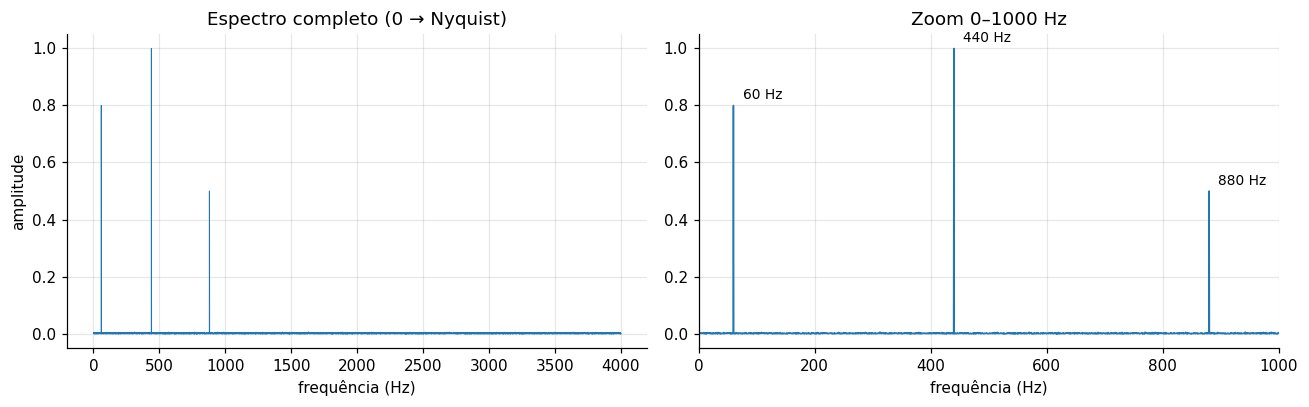

In [7]:
def espectro(sig, fs):
    # retorna (frequências, amplitude) do espectro unilateral
    N = len(sig)
    X = fft.rfft(sig)
    f = fft.rfftfreq(N, 1/fs)
    amp = 2*np.abs(X)/N
    amp[0] /= 2
    return f, amp

f, Ax = espectro(x, fs)
print(f"N = {len(x)} amostras | Δf = {f[1]:.2f} Hz | Nyquist = {fs/2:.0f} Hz")

picos, _ = signal.find_peaks(Ax, height=0.2)
print("\nPicos detectados:")
for p in picos:
    print(f"  {f[p]:7.1f} Hz  ->  amplitude {Ax[p]:.3f}")
piso = np.median(Ax)
print(f"\nPiso de ruído (mediana do espectro): {piso:.4f}  (≈ {20*np.log10(piso):.1f} dB)")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].plot(f, Ax, lw=0.7); axs[0].set(title="Espectro completo (0 → Nyquist)", xlabel="frequência (Hz)", ylabel="amplitude")
axs[1].plot(f, Ax, lw=1); axs[1].set(xlim=(0, 1000), title="Zoom 0–1000 Hz", xlabel="frequência (Hz)")
for p in picos:
    axs[1].annotate(f"{f[p]:.0f} Hz", (f[p], Ax[p]), textcoords="offset points", xytext=(6, 4), fontsize=9)
plt.tight_layout(); plt.show()

**Interpretação.** O espectro organiza o que o gráfico temporal escondia:

- **440 Hz (amp. 1,0)** e **880 Hz (amp. 0,5)**: a nota e seu 2º harmônico, exatamente as amplitudes com que foram geradas. É o "timbre" do sinal.
- **60 Hz (amp. 0,8)**: o zumbido da rede. No tempo era a oscilação lenta (período 16,7 ms); aqui é um pico estreito, isolado, fácil de atacar.
- **Piso plano** em toda a banda até 4000 Hz: o ruído branco. Ele é pequeno **em cada bin**, mas ocupa a banda inteira, e por isso soma muita energia. Isso guia o projeto do filtro: um *notch* em 60 Hz para a interferência estreita e um **passa-baixas** acima do último harmônico útil (880 Hz) para cortar a maior parte do ruído.

**Por que os picos saem tão limpos?** Todas as frequências são múltiplos inteiros de $1/T=0{,}5$ Hz, então cabem um número inteiro de ciclos na janela e não há *vazamento espectral*. Com frequências fora da grade seria preciso usar uma janela (Hann, Hamming…).

### 2.1 Taxa de amostragem e Nyquist (demonstração de *aliasing*)

Tom real: 70 Hz | fs = 100 Hz | pico medido em 30 Hz  (alias: |70 − 100| = 30 Hz)


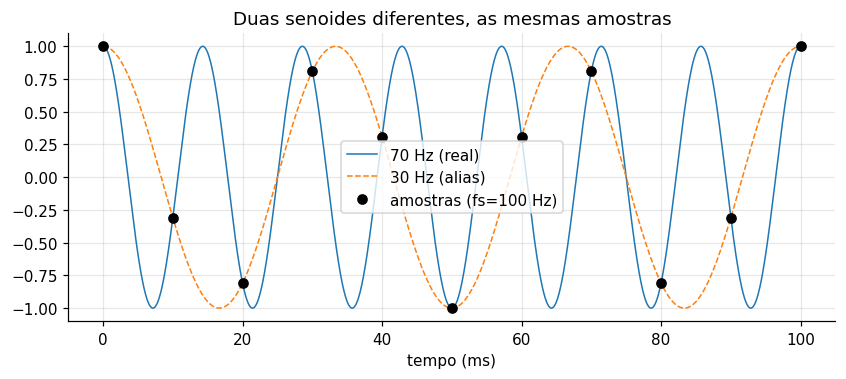

In [8]:
# Um tom de 70 Hz amostrado a apenas 100 Hz (Nyquist = 50 Hz) "aparece" em 30 Hz
fs_ruim = 100
tb = np.arange(0, 1, 1/fs_ruim)
xb = np.cos(2*np.pi*70*tb)
fb, Ab = espectro(xb, fs_ruim)
print(f"Tom real: 70 Hz | fs = {fs_ruim} Hz | pico medido em {fb[np.argmax(Ab)]:.0f} Hz  (alias: |70 − 100| = 30 Hz)")

tf = np.linspace(0, 0.1, 2000)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(tf*1e3, np.cos(2*np.pi*70*tf), label="70 Hz (real)", lw=1)
ax.plot(tf*1e3, np.cos(2*np.pi*30*tf), label="30 Hz (alias)", lw=1, ls="--")
ax.plot(tb[:11]*1e3, xb[:11], "ko", label=f"amostras (fs={fs_ruim} Hz)")
ax.set(xlabel="tempo (ms)", title="Duas senoides diferentes, as mesmas amostras"); ax.legend(); plt.show()

**Interpretação.** Com $f_s=100$ Hz, o tom de 70 Hz viola Nyquist ($70>f_s/2=50$) e se "dobra" para $|70-100|=30$ Hz. As amostras (pontos) pertencem tanto à senoide de 70 Hz quanto à de 30 Hz: depois de amostrado, **não há como distinguir**. No nosso sinal, $f_s=8000$ Hz dá Nyquist em 4000 Hz, bem acima de 880 Hz, então não há aliasing. Por isso guardamos `fs`: sem ela o eixo de frequência não faz sentido.

---
# Etapa 3 · Filtrar e reconstruir (Unidade 3)

Do espectro da Etapa 2 tiramos as **especificações**:

1. **Rejeita-faixa (notch) em 60 Hz**, estreito, para eliminar o zumbido sem tocar nos 440/880 Hz.
2. **Passa-baixas em 1500 Hz**: preserva 440 e 880 Hz e corta o ruído acima deles (≈ 62 % da banda).

Faremos de **duas formas** e compararemos:

- **(A) Filtro no domínio da frequência:** zerar bins da FFT e reconstruir com a **IFFT**:
  $x[m]=\frac1N\sum_k X[k]\,e^{j2\pi km/N}$, que é a aplicação direta do que aprendemos.
- **(B) Filtro IIR no domínio do tempo:** notch + Butterworth de 4ª ordem (é o que um sistema em tempo real usaria, e é o que modelaremos com Laplace na Etapa 4).

In [9]:
# ---------- (A) Filtro espectral + IFFT ----------
X = fft.rfft(x)
fx = fft.rfftfreq(len(x), 1/fs)
H_esp = np.ones_like(fx)
H_esp[(fx >= 59) & (fx <= 61)] = 0      # notch em 60 Hz  (±1 Hz)
H_esp[fx > 1500] = 0                    # passa-baixas em 1500 Hz
y_fft = fft.irfft(X*H_esp, n=len(x))    # Transformada Inversa

# ---------- (B) Filtro IIR (notch + Butterworth 4ª ordem), fase zero ----------
Q_notch = 30
b_n, a_n = signal.iirnotch(60, Q_notch, fs=fs)
sos_notch = signal.tf2sos(b_n, a_n)
sos_lp = signal.butter(4, 1500, btype="low", fs=fs, output="sos")
sos = np.vstack([sos_notch, sos_lp])
y_iir = signal.sosfiltfilt(sos, x)      # filtfilt => sem defasagem (aplica o filtro 2x)

# ---------- Métrica objetiva: SNR em relação ao sinal limpo ----------
def snr_db(sig, ref):
    return 10*np.log10(np.sum(ref**2)/np.sum((sig - ref)**2))

print("SNR (dB) — quanto maior, melhor")
print(f"  antes (ruidoso)            : {snr_db(x, limpo):6.2f} dB")
print(f"  depois (A) FFT + IFFT      : {snr_db(y_fft, limpo):6.2f} dB")
print(f"  depois (B) IIR notch + LP  : {snr_db(y_iir, limpo):6.2f} dB")

salvar_wav("data/depois_fft.wav", y_fft, ESC)
salvar_wav("data/depois_iir.wav", y_iir, ESC)

SNR (dB) — quanto maior, melhor
  antes (ruidoso)            :   2.62 dB
  depois (A) FFT + IFFT      :  18.57 dB
  depois (B) IIR notch + LP  :  17.58 dB


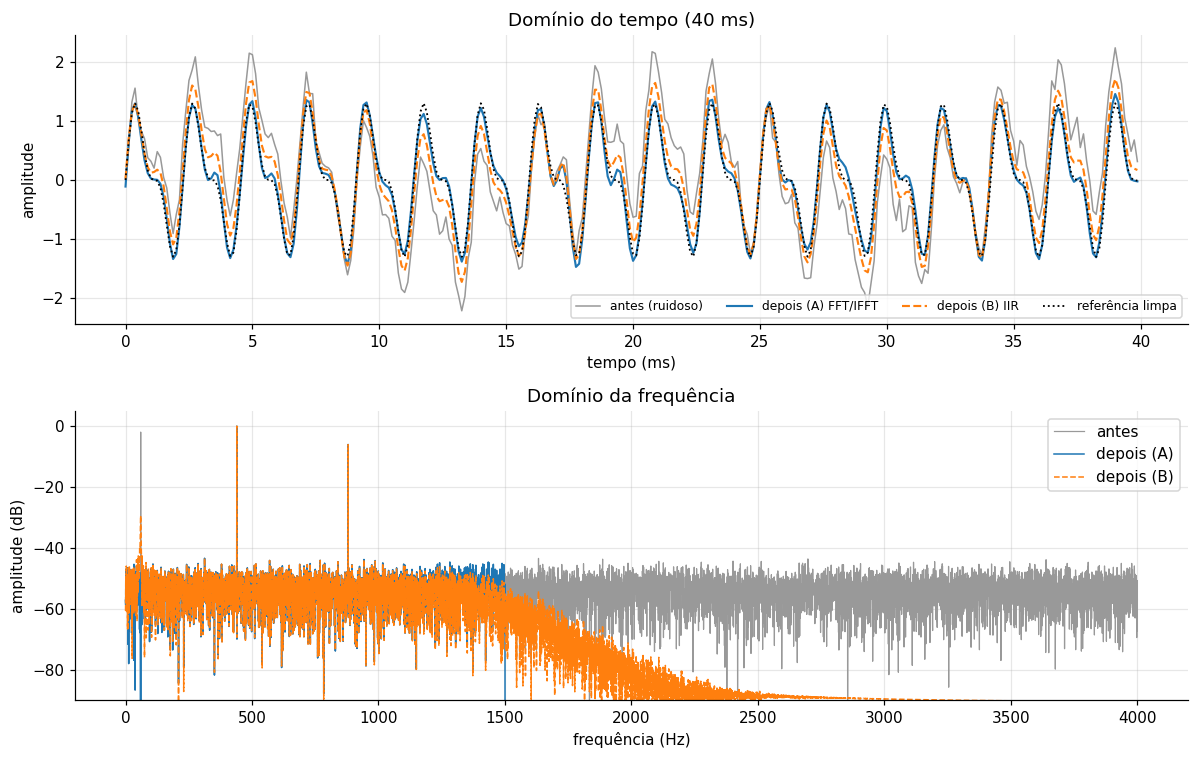

In [10]:
fig, axs = plt.subplots(2, 1, figsize=(11, 7))
m = t < 0.04
axs[0].plot(t[m]*1e3, x[m], color="0.6", lw=1, label="antes (ruidoso)")
axs[0].plot(t[m]*1e3, y_fft[m], lw=1.4, label="depois (A) FFT/IFFT")
axs[0].plot(t[m]*1e3, y_iir[m], lw=1.4, ls="--", label="depois (B) IIR")
axs[0].plot(t[m]*1e3, limpo[m], "k:", lw=1.2, label="referência limpa")
axs[0].set(title="Domínio do tempo (40 ms)", xlabel="tempo (ms)", ylabel="amplitude"); axs[0].legend(ncol=4, fontsize=8)

_, Ay_fft = espectro(y_fft, fs); _, Ay_iir = espectro(y_iir, fs)
db = lambda a: 20*np.log10(a + 1e-9)
axs[1].plot(f, db(Ax), color="0.6", lw=0.8, label="antes")
axs[1].plot(f, db(Ay_fft), lw=1, label="depois (A)")
axs[1].plot(f, db(Ay_iir), lw=1, ls="--", label="depois (B)")
axs[1].set(title="Domínio da frequência", xlabel="frequência (Hz)", ylabel="amplitude (dB)", ylim=(-90, 5)); axs[1].legend()
plt.tight_layout(); plt.show()

**Interpretação.**

- **Tempo:** antes, a forma de onda está "torta" (zumbido) e "serrilhada" (ruído); depois, as duas filtragens se sobrepõem à referência limpa (linha pontilhada) e o deslocamento lento do zumbido desaparece.
- **Frequência:** o pico de 60 Hz some (uma queda de dezenas de dB) e tudo acima de 1500 Hz cai para o piso do numérico; 440 e 880 Hz ficam intactos. O **SNR sobe de ≈ 2–3 dB para ≈ 17–19 dB**. O ganho vem de duas fontes: remover 60 Hz (a maior parte da potência indesejada) e cortar cerca de 62 % da banda de ruído branco.
- **(A) vs (B):** os resultados são muito próximos. O filtro espectral é "perfeito" neste caso porque o sinal é periódico na janela; em sinais reais, cortar bins abruptamente gera *ringing* (Gibbs, Etapa 1.3), e o IIR suave é a escolha robusta, além de funcionar em tempo real.
- **Por que `filtfilt`?** Um filtro causal introduz atraso de fase. `sosfiltfilt` aplica o filtro "para frente e para trás", cancelando a fase (e elevando a magnitude ao quadrado).

**Escute:** os três áudios abaixo têm o mesmo volume.

In [11]:
print("Antes (ruidoso):");  display(Audio(x*ESC, rate=fs))
print("Depois (FFT + IFFT):"); display(Audio(y_fft*ESC, rate=fs))
print("Depois (IIR):");      display(Audio(y_iir*ESC, rate=fs))
print("Referência limpa:");  display(Audio(limpo*ESC, rate=fs))

Antes (ruidoso):


Depois (FFT + IFFT):


Depois (IIR):


Referência limpa:


---
# Etapa 4 · O filtro como sistema linear (Unidade 4)

Um sistema linear e invariante no tempo (LIT) é descrito por uma EDO linear. A **Transformada de Laplace** $F(s)=\int_0^\infty f(t)e^{-st}dt$ transforma derivadas em multiplicações por $s$ (com condições iniciais nulas) e a EDO vira uma **álgebra**:

$$H(s)=\frac{Y(s)}{X(s)}=\frac{\text{polinômio em }s}{\text{polinômio em }s}$$

- **Zeros** = raízes do numerador → frequências que o sistema **anula**.
- **Polos** = raízes do denominador → modos naturais; definem **estabilidade** e **seletividade**.
- **Estável** ⇔ todos os polos com $\operatorname{Re}(s)<0$ (semiplano esquerdo).
- **Resposta em frequência:** $H(j\omega)$, isto é, $H(s)$ avaliada sobre o eixo imaginário. *É aqui que a Etapa 4 encontra a Etapa 2.*

### 4.1 Aquecimento: filtro RC de 1ª ordem
$RC\,\dot y+y=x \;\Rightarrow\; H(s)=\dfrac1{RCs+1}$. Conferindo com a Laplace da resposta ao impulso $h(t)=\frac1{RC}e^{-t/RC}$:

In [12]:
s = sp.symbols("s")
tt = sp.symbols("t", positive=True)
R, C = sp.symbols("R C", positive=True)

h_rc = sp.exp(-tt/(R*C))/(R*C)
H_rc = sp.simplify(sp.laplace_transform(h_rc, tt, s, noconds=True))
display(sp.Eq(sp.Function("H")(s), H_rc))
print("Polo em s = -1/(RC); zero: nenhum. Corte: fc = 1/(2πRC).")

# Laplace inversa: volta de H(s) para h(t)
display(sp.Eq(sp.Function("h")(tt), sp.inverse_laplace_transform(H_rc, s, tt)))

           1    
H(s) = ─────────
       C⋅R⋅s + 1

Polo em s = -1/(RC); zero: nenhum. Corte: fc = 1/(2πRC).


        -t 
        ───
        C⋅R
       ℯ   
h(t) = ────
       C⋅R 

### 4.2 Por que o polo no semiplano esquerdo = estável?
A inversa de $\dfrac{1}{s-p}$ é $e^{pt}$. Veja a resposta ao impulso para três posições do polo:

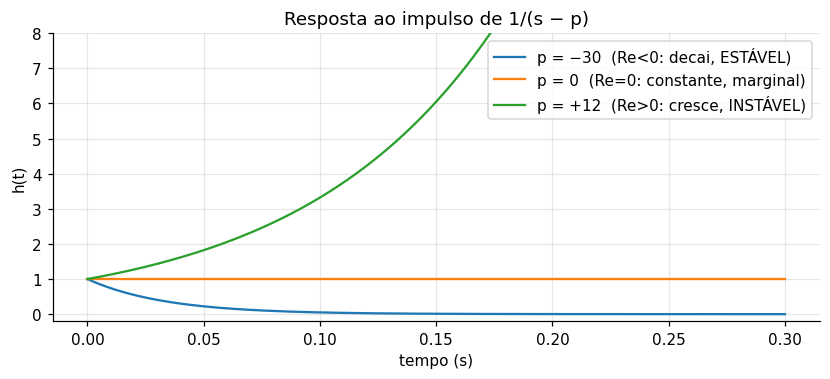

In [13]:
Tt = np.linspace(0, 0.3, 600)
fig, ax = plt.subplots(figsize=(9, 3.4))
for p, nome in [(-30, "p = −30  (Re<0: decai, ESTÁVEL)"), (0, "p = 0  (Re=0: constante, marginal)"), (+12, "p = +12  (Re>0: cresce, INSTÁVEL)")]:
    _, h = signal.impulse(([1], [1, -p]), T=Tt)
    ax.plot(Tt, h, label=nome)
ax.set(ylim=(-0.2, 8), xlabel="tempo (s)", ylabel="h(t)", title="Resposta ao impulso de 1/(s − p)"); ax.legend(); plt.show()

**Interpretação.** $\operatorname{Re}(p)<0$ dá uma exponencial decrescente (o sistema "esquece" a entrada); $\operatorname{Re}(p)=0$ não decai; $\operatorname{Re}(p)>0$ explode. É por isso que um filtro físico precisa ter **todos** os polos à esquerda do eixo $j\omega$.

### 4.3 O filtro notch analógico de 2ª ordem

O notch que usamos na Etapa 3 corresponde ao sistema

$$\ddot y+\frac{\omega_0}{Q}\dot y+\omega_0^2\,y=\ddot x+\omega_0^2\,x$$

Aplicando Laplace nos dois lados (condições iniciais nulas):
$$\big(s^2+\tfrac{\omega_0}{Q}s+\omega_0^2\big)Y(s)=\big(s^2+\omega_0^2\big)X(s)\;\Rightarrow\;H_{\text{notch}}(s)=\frac{s^2+\omega_0^2}{s^2+\frac{\omega_0}{Q}s+\omega_0^2}$$

In [14]:
w0s, Qs = sp.symbols("omega_0 Q", positive=True)
Xs, Ys = sp.symbols("X Y")

eq = sp.Eq(Ys*(s**2 + w0s/Qs*s + w0s**2), Xs*(s**2 + w0s**2))
H_notch = sp.simplify(sp.solve(eq, Ys)[0]/Xs)
display(sp.Eq(sp.Function("H_notch")(s), H_notch))

# Polos e zeros simbólicos
zeros_sym = sp.solve(sp.numer(sp.together(H_notch)), s)
polos_sym = sp.solve(sp.denom(sp.together(H_notch)), s)
print("Zeros :", zeros_sym)
print("Polos :")
for p_ in polos_sym: display(sp.simplify(p_))

                  ⎛  2    2⎞    
                Q⋅⎝ω₀  + s ⎠    
H_notch(s) = ───────────────────
                 2      2       
             Q⋅ω₀  + Q⋅s  + ω₀⋅s

Zeros : [-I*omega_0, I*omega_0]
Polos :


   ⎛   __________    ⎞
   ⎜  ╱        2     ⎟
ω₀⋅⎝╲╱  1 - 4⋅Q   - 1⎠
──────────────────────
         2⋅Q          

    ⎛   __________    ⎞ 
    ⎜  ╱        2     ⎟ 
-ω₀⋅⎝╲╱  1 - 4⋅Q   + 1⎠ 
────────────────────────
          2⋅Q           

**Leitura simbólica.**
- **Zeros:** $s=\pm j\omega_0$, **exatamente sobre o eixo imaginário**. Como $H(j\omega_0)=0$, o sistema anula por completo uma senoide de frequência $\omega_0$.
- **Polos:** $s=-\dfrac{\omega_0}{2Q}\pm j\,\omega_0\sqrt{1-\dfrac1{4Q^2}}$. Ficam **à esquerda** do eixo, bem perto dos zeros quando $Q$ é grande.
- A parte real do polo, $\sigma=-\omega_0/2Q$, controla a **largura** do notch: $\text{BW}_{-3\,dB}=\omega_0/Q$.

### 4.4 O sistema completo: notch (60 Hz) × Butterworth de 4ª ordem (1500 Hz)
Filtros em cascata multiplicam suas funções de transferência: $H(s)=H_{\text{notch}}(s)\cdot H_{\text{LP}}(s)$.

ZEROS (rad/s):
  -0.00+376.99j
  0.00-376.99j
POLOS (rad/s):
  -6.28+376.94j
  -6.28-376.94j
  -3606.71+8707.36j
  -8707.36+3606.71j
  -8707.36-3606.71j
  -3606.71-8707.36j

Todos os polos com Re(s) < 0 ?  -> True   => sistema ESTÁVEL
Polo do notch: σ = −ω0/(2Q) = -6.28 rad/s  (calculado: -6.28)


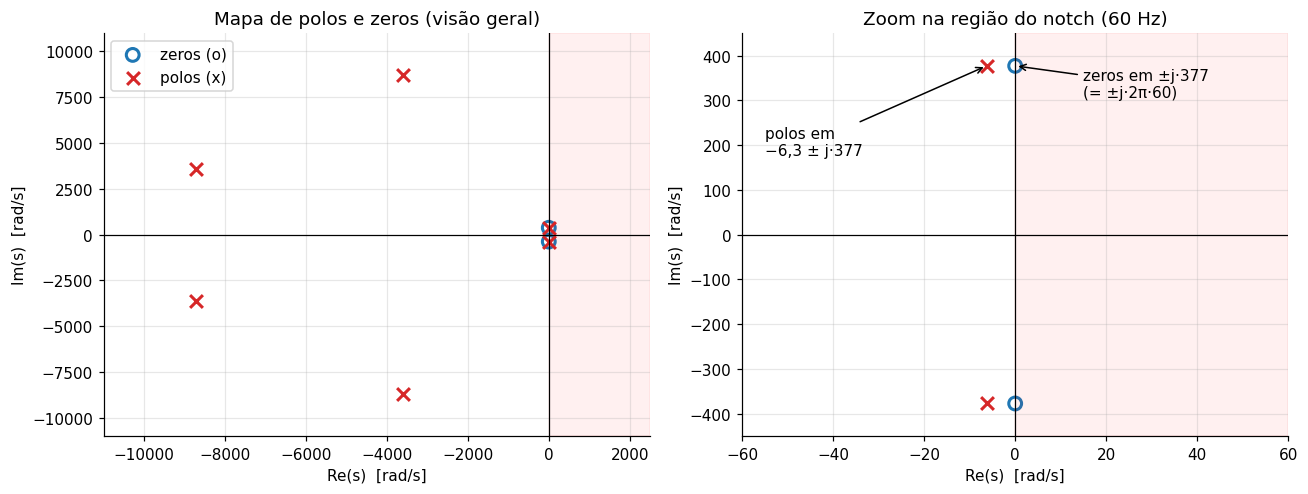

In [15]:
w0 = 2*np.pi*60
Qn = Q_notch                       # mesmo Q usado na Etapa 3

# Notch:  zeros/polos/ganho
z_n, p_n, k_n = signal.tf2zpk([1, 0, w0**2], [1, w0/Qn, w0**2])
# Butterworth analógico de 4ª ordem com fc = 1500 Hz
z_l, p_l, k_l = signal.butter(4, 2*np.pi*1500, btype="low", analog=True, output="zpk")

Z = np.concatenate([z_n, z_l]); P = np.concatenate([p_n, p_l]); K = k_n*k_l

print("ZEROS (rad/s):"); [print(f"  {z:10.2f}") for z in Z]
print("POLOS (rad/s):"); [print(f"  {p:10.2f}") for p in P]
print("\nTodos os polos com Re(s) < 0 ?  ->", bool(np.all(P.real < 0)), "  => sistema", "ESTÁVEL" if np.all(P.real < 0) else "INSTÁVEL")
print(f"Polo do notch: σ = −ω0/(2Q) = {-w0/(2*Qn):.2f} rad/s  (calculado: {p_n[0].real:.2f})")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, lim, tit in [(axs[0], 11000, "Mapa de polos e zeros (visão geral)"), (axs[1], None, "Zoom na região do notch (60 Hz)")]:
    ax.axvline(0, color="k", lw=0.8); ax.axhline(0, color="k", lw=0.8)
    ax.scatter(Z.real, Z.imag, s=70, facecolors="none", edgecolors="tab:blue", linewidths=2, label="zeros (o)")
    ax.scatter(P.real, P.imag, s=70, marker="x", color="tab:red", linewidths=2, label="polos (x)")
    ax.set(title=tit, xlabel="Re(s)  [rad/s]", ylabel="Im(s)  [rad/s]")
    if lim: ax.set(xlim=(-lim, 2500), ylim=(-lim, lim))
    else:   ax.set(xlim=(-60, 60), ylim=(-450, 450))
    ax.axvspan(0, 2500 if lim else 60, color="red", alpha=0.06)
axs[0].legend(loc="upper left"); axs[1].annotate("zeros em ±j·377\n(= ±j·2π·60)", (0, w0), (15, w0-70), arrowprops=dict(arrowstyle="->"))
axs[1].annotate("polos em\n−6,3 ± j·377", (p_n[0].real, p_n[0].imag), (-55, w0-200), arrowprops=dict(arrowstyle="->"))
plt.tight_layout(); plt.show()

**Interpretação do mapa.**
- **Zoom (direita):** dois zeros sobre o eixo $j\omega$ em $\pm j\,2\pi\cdot60$ e dois polos colados neles, ligeiramente à esquerda ($\sigma\approx-6{,}3$ rad/s). Sobre o eixo imaginário, o zero zera a resposta; o polo vizinho "desfaz" o efeito nas frequências um pouco afastadas. O resultado é um buraco **estreito**.
- **Visão geral (esquerda):** os 4 polos do Butterworth (cruzes vermelhas mais à esquerda) ficam num **semicírculo de raio $2\pi\cdot1500\approx9425$ rad/s** no semiplano esquerdo, característica dos filtros de Butterworth.
- **Estabilidade:** **todos os polos têm $\operatorname{Re}(s)<0$ ⇒ o sistema é estável** (região sombreada em vermelho = semiplano direito, proibido).

### 4.5 Da posição dos polos à resposta em frequência (Etapa 4 ↔ Etapa 2)

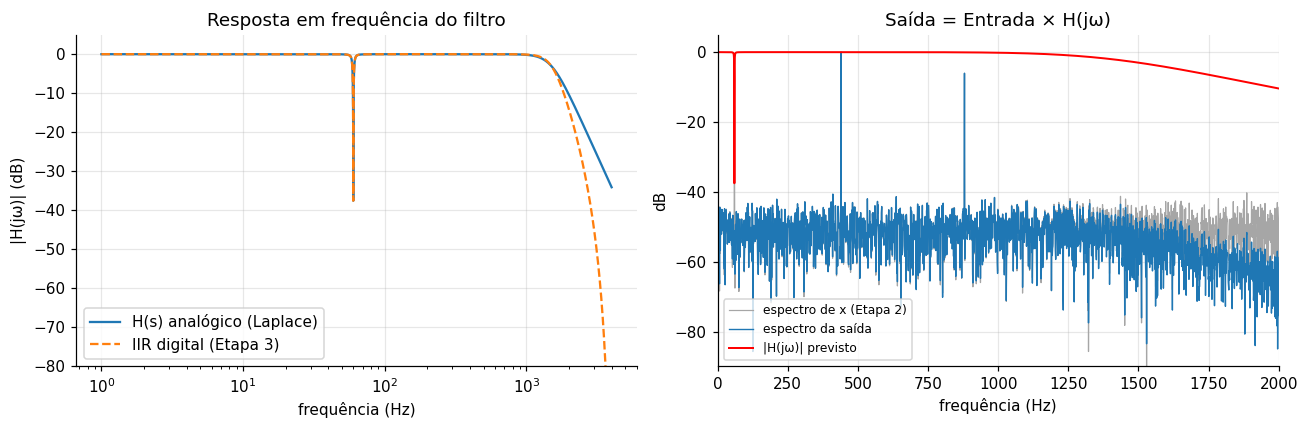

 f (Hz) | |X| medido |  |H(jω)| |  |X|·|H| | |Y| medido
     60 |     0.7993 |   0.0000 |   0.0000 |     0.0020
    440 |     0.9984 |   1.0000 |   0.9984 |     0.9984
    880 |     0.4998 |   0.9931 |   0.4963 |     0.4980


In [16]:
fh = np.linspace(1, 4000, 40000)
w, Ha = signal.freqs_zpk(Z, P, K, worN=2*np.pi*fh)             # H(jω) analógico
_, Hd = signal.sosfreqz(sos, worN=fh, fs=fs)                   # filtro digital (Etapa 3, 1 passagem)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].semilogx(fh, 20*np.log10(np.abs(Ha)+1e-12), label="H(s) analógico (Laplace)")
axs[0].semilogx(fh, 20*np.log10(np.abs(Hd)+1e-12), "--", label="IIR digital (Etapa 3)")
axs[0].set(ylim=(-80, 5), xlabel="frequência (Hz)", ylabel="|H(jω)| (dB)", title="Resposta em frequência do filtro"); axs[0].legend()

# Espectro medido (Etapa 2) × resposta prevista pelos polos/zeros
# Usamos a 2ª metade do sinal (1 s) para excluir o transitório do filtro
seg = slice(fs, None)
y_ss = signal.sosfilt(sos, x)                                   # filtro causal, 1 passagem
f1, A_in = espectro(x[seg], fs); _, A_out = espectro(y_ss[seg], fs)
axs[1].plot(f1, db(A_in), color="0.65", lw=0.8, label="espectro de x (Etapa 2)")
axs[1].plot(f1, db(A_out), lw=0.9, label="espectro da saída")
axs[1].plot(fh, 20*np.log10(np.abs(Ha)+1e-12), "r", lw=1.3, label="|H(jω)| previsto")
axs[1].set(xlim=(0, 2000), ylim=(-90, 5), xlabel="frequência (Hz)", ylabel="dB", title="Saída = Entrada × H(jω)"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Conferência numérica nos picos: |Y| ≈ |X|·|H|
print(f"{'f (Hz)':>7} | {'|X| medido':>10} | {'|H(jω)|':>8} | {'|X|·|H|':>8} | {'|Y| medido':>10}")
for fp in (60, 440, 880):
    i = np.argmin(np.abs(f1 - fp)); Hm = np.abs(signal.freqs_zpk(Z, P, K, worN=[2*np.pi*fp])[1][0])
    print(f"{fp:7d} | {A_in[i]:10.4f} | {Hm:8.4f} | {A_in[i]*Hm:8.4f} | {A_out[i]:10.4f}")

**Interpretação: "a mesma história em duas linguagens".**

- A curva vermelha $|H(j\omega)|$ foi calculada **apenas** com polos e zeros (Laplace). O espectro medido pela FFT na saída do filtro (Etapa 2) segue exatamente essa curva: **saída = entrada × $H(j\omega)$**, e a tabela confirma pico a pico ($|Y|\approx|X|\cdot|H|$).
- **60 Hz:** zero em $\pm j\,2\pi60$ ⇒ $H(j2\pi60)=0$ ⇒ o pico que víamos na Etapa 2 desaparece (o que resta é ruído numérico/transitório).
- **440 e 880 Hz:** longe de polos e zeros do notch e dentro da banda do Butterworth ⇒ ganho ≈ 1 (0 dB).
- **> 1500 Hz:** os 4 polos do Butterworth fazem o ganho cair a 80 dB/década, o que corresponde ao corte do ruído branco que vimos como piso do espectro.
- O filtro **digital** da Etapa 3 (tracejado) e o **analógico** de Laplace coincidem em toda a região de interesse (notch e banda passante), pois o digital é a discretização (transformação bilinear) do analógico. Só perto de Nyquist (4 kHz) o digital cai mais rápido, por causa da distorção de frequência da bilinear, que mapeia $\omega\to\infty$ em $f_s/2$. As duas linguagens descrevem o mesmo sistema.

### 4.6 Quanto vale o Q? A distância do polo ao eixo controla a largura

    Q |  Re(polo) rad/s |  BW teórica f0/Q (Hz) |  BW medida -3 dB (Hz)
    3 |          -62.83 |                 20.00 |                 20.00
   10 |          -18.85 |                  6.00 |                  6.00
   30 |           -6.28 |                  2.00 |                  2.00
  100 |           -1.88 |                  0.60 |                  0.60


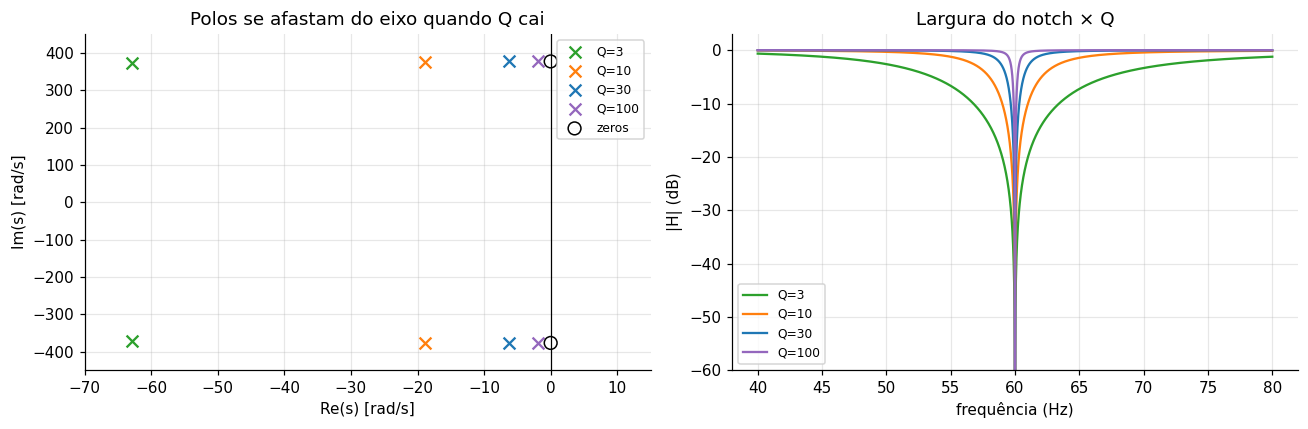

In [17]:
fz = np.linspace(40, 80, 200001)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
print(f"{'Q':>5} | {'Re(polo) rad/s':>15} | {'BW teórica f0/Q (Hz)':>21} | {'BW medida -3 dB (Hz)':>21}")
for Qv, cor in zip([3, 10, 30, 100], ["tab:green", "tab:orange", "tab:blue", "tab:purple"]):
    zz, pp, kk = signal.tf2zpk([1, 0, w0**2], [1, w0/Qv, w0**2])
    _, Hq = signal.freqs_zpk(zz, pp, kk, worN=2*np.pi*fz)
    mag = np.abs(Hq)
    bw = fz[mag < 1/np.sqrt(2)]
    print(f"{Qv:5d} | {pp[0].real:15.2f} | {60/Qv:21.2f} | {bw.max()-bw.min():21.2f}")
    axs[0].scatter(pp.real, pp.imag, marker="x", s=60, color=cor, label=f"Q={Qv}")
    axs[1].plot(fz, 20*np.log10(mag + 1e-6), color=cor, label=f"Q={Qv}")
axs[0].scatter([0, 0], [w0, -w0], facecolors="none", edgecolors="k", s=70, label="zeros")
axs[0].axvline(0, color="k", lw=0.8)
axs[0].set(xlim=(-70, 15), ylim=(-450, 450), xlabel="Re(s) [rad/s]", ylabel="Im(s) [rad/s]", title="Polos se afastam do eixo quando Q cai"); axs[0].legend(fontsize=8)
axs[1].set(ylim=(-60, 3), xlabel="frequência (Hz)", ylabel="|H| (dB)", title="Largura do notch × Q"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretação.** Quanto **maior** o $Q$, mais o polo encosta no zero (parte real menor em módulo) e **mais estreito** é o buraco em 60 Hz: a largura de −3 dB medida coincide com $f_0/Q$. Há um *trade-off*: Q alto preserva melhor o sinal vizinho, mas exige que o zumbido seja muito estável em 60 Hz (se a rede variar para 59,8 Hz, um notch estreito demais deixa escapar parte dele) e produz resposta ao impulso mais longa (polos perto do eixo ⇒ decaimento lento, $e^{-\omega_0 t/2Q}$).

---
# Conclusão

| Etapa | O que fizemos | O que aprendemos |
|---|---|---|
| 1 | Série de Fourier (trig. e complexa) da onda quadrada | Senoides/exponenciais são uma **base ortogonal**; descontinuidades geram **Gibbs** (≈ 8,95 %) que não some com mais termos. |
| 2 | FFT do sinal, espectro, Nyquist | O que é confuso no tempo fica **separado** na frequência; `fs` define o eixo e o limite de Nyquist evita *aliasing*. |
| 3 | Notch 60 Hz + passa-baixas, IFFT / IIR | Projetamos o filtro **a partir do espectro**; SNR subiu de ≈ 2–3 dB para ≈ 17–19 dB; o filtro suave (IIR) evita o *ringing* do corte abrupto. |
| 4 | H(s) via Laplace, polos/zeros, estabilidade | **Zero no eixo jω = anulação exata**; **polo à esquerda = estável**; distância do polo ao eixo = largura/seletividade. A resposta em frequência da Etapa 2 sai da geometria de polos e zeros. |

**Limitações e próximos passos.** O sinal é sintético (sabemos a resposta certa); em sinais reais (voz, ECG) a frequência do zumbido varia, o ruído não é branco e seria interessante testar um notch adaptativo, janelas (Hann) na FFT e comparar Butterworth × Chebyshev × FIR.

**Arquivos gerados em `data/`:** `sinal_ruidoso.csv`, `antes_ruidoso.wav`, `depois_fft.wav`, `depois_iir.wav`, `limpo_referencia.wav`.